In [72]:
import functools
import qiskit_dynamics as qk_d
import qiskit.providers.fake_provider as qk_fp
import numpy as np
import csv
import qiskit
import matplotlib.pyplot as plt
import pulse_simulator as ps

from qiskit.quantum_info import Operator, process_fidelity, SuperOp

In [73]:
backend = qk_fp.FakeManila()
units = 1e9
ns = units
dt = backend.configuration().dt * ns

# Bernstein-Vazirani Circuit Simulations

In [74]:
def bv_circuit(num_qubits: int, s: str, measure: bool=False) -> qiskit.QuantumCircuit:
    """
    From: https://github.com/qiskit-community/qiskit-textbook/blob/main/content/ch-algorithms/bernstein-vazirani.ipynb.
    """
    qc = qiskit.QuantumCircuit(num_qubits+1)
    qc.h(num_qubits)
    qc.z(num_qubits)

    for i in range(num_qubits):
        qc.h(i)

    s = s[::-1] # reverse s to fit qiskit's qubit ordering
    for q in range(num_qubits):
        if not (s[q] == '0'):
            qc.cx(q, num_qubits)

    for i in range(num_qubits):
        qc.h(i)
    if measure:
        for i in range(num_qubits):
            qc.measure(i, i)

    return qc

In [75]:
qc = bv_circuit(2, "11")
qc.draw()

┌───┐          ┌───┐     
q_0: ┤ H ├───────■──┤ H ├─────
     ├───┤       │  └───┘┌───┐
q_1: ┤ H ├───────┼────■──┤ H ├
     ├───┤┌───┐┌─┴─┐┌─┴─┐└───┘
q_2: ┤ H ├┤ Z ├┤ X ├┤ X ├─────
     └───┘└───┘└───┘└───┘

# Simulators

In [76]:
Z = np.array([[1, 0], [0, -1]], dtype=np.complex128)
I = np.array([[1, 0], [0, 1]], dtype=np.complex128)

def get_zz_edge(num_qubits: int, edge: tuple[int, int]): 
    if 0 in edge:
        H = Z
    else:
        H = I

    for i in range(1, num_qubits):
        if i in edge:
            H = np.kron(H, Z)
        else:
            H = np.kron(H, I)

    return H

def get_xtalk(num_qubits: int, edges: list[tuple[int, int]], coefficient: float=1.0):
    H_xtalk = np.zeros((2 ** num_qubits, 2 ** num_qubits), dtype=np.complex128)
    for edge in edges:
        H_xtalk += coefficient * get_zz_edge(num_qubits, edge)
    return H_xtalk


In [77]:
get_xtalk(2, [(0, 1)], 0.001)

array([[ 0.001+0.j,  0.   +0.j,  0.   +0.j,  0.   +0.j],
       [ 0.   +0.j, -0.001+0.j,  0.   +0.j,  0.   +0.j],
       [ 0.   +0.j,  0.   +0.j, -0.001+0.j,  0.   +0.j],
       [ 0.   +0.j,  0.   +0.j,  0.   +0.j,  0.001+0.j]])

In [78]:
N = 3
registers = [i for i in range(N)]
config_vars = ps.backend_simulation_vars(backend, rabi=False, units=units)

cr_model = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=config_vars,
    model_name="Toy",
    qiskit_order=True,
)

# Control model
H_drift = 0.0
Hs_control = []
Hs_channels = []
for i in range(N - 1):
    # control-target
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (i, i + 1), return_params=True
    )
    H_drift += Hj_drift
    for c_i in range(len(Hjs_channel)):
        if Hjs_channel[c_i] in Hs_channels:
            continue
        else:
            # print(Hjs_channel[c_i])
            Hs_control += [Hjs_control[c_i]]
            Hs_channels += [Hjs_channel[c_i]]
    # print(params)

    # target-control
    Hj_drift, Hjs_control, Hjs_channel, params = cr_model(
        (i + 1, i), return_params=True
    )
    H_drift += Hj_drift
    for c_i in range(len(Hjs_channel)):
        if Hjs_channel[c_i] in Hs_channels:
            continue
        else:
            # print(Hjs_channel[c_i])
            Hs_control += [Hjs_control[c_i]]
            Hs_channels += [Hjs_channel[c_i]]
    # print(params)


In [79]:
A_decay = functools.partial(
    ps.qubit_decay_model,
    registers=registers, 
    variables=config_vars
)

As_static = []

for qubit in range(N):    
    Ajs_static = A_decay(qubit)
    As_static += Ajs_static

In [80]:
solver = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
    dt=dt,
)
solver.model.evaluation_mode = "dense"

In [81]:
robust_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

In [82]:
# load and set one-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-6.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    robust_sim.set_pulse(name, qiskit_pulse)

# load and set two-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_robust.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

rzx_p = qiskit.pulse.Waveform(gates[0], limit_amplitude=False)
rzx_n = qiskit.pulse.Waveform(-gates[0], limit_amplitude=False)
robust_sim.set_pulse("zx+_blue", rzx_p)
robust_sim.set_pulse("zx+_red", rzx_p)
robust_sim.set_pulse("zx-_blue", rzx_n)
robust_sim.set_pulse("zx-_red", rzx_n)

In [83]:
default_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

In [84]:
# load and set one-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    default_sim.set_pulse(name, qiskit_pulse)

# load and set two-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

rzx_p = qiskit.pulse.Waveform(gates[0], limit_amplitude=False)
rzx_n = qiskit.pulse.Waveform(-gates[0], limit_amplitude=False)
default_sim.set_pulse("zx+_blue", rzx_p)
default_sim.set_pulse("zx+_red", rzx_p)
default_sim.set_pulse("zx-_blue", rzx_n)
default_sim.set_pulse("zx-_red", rzx_n)

In [85]:
mixed_sim = ps.simulator.Simulator(
    basis_gates=["rz", "sx", "x", "ecr"], solver=solver, backend=backend
)

In [86]:
# load and set one-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_default.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

for pulse, name in zip(gates, ["x_blue", "x_red", "sx_blue", "sx_red"]):
    qiskit_pulse = qiskit.pulse.Waveform(pulse, limit_amplitude=False)
    mixed_sim.set_pulse(name, qiskit_pulse)

# load and set two-qubit pulses
file_name = "../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_robust.csv"
gates = []
with open(file_name) as file:
    reader = csv.reader(file)
    for row in reader:
        gates.append(np.array([float(x) for x in row]))

rzx_p = qiskit.pulse.Waveform(gates[0], limit_amplitude=False)
rzx_n = qiskit.pulse.Waveform(-gates[0], limit_amplitude=False)
mixed_sim.set_pulse("zx+_blue", rzx_p)
mixed_sim.set_pulse("zx+_red", rzx_p)
mixed_sim.set_pulse("zx-_blue", rzx_n)
mixed_sim.set_pulse("zx-_red", rzx_n)

# Simulations

In [88]:
compiled_qc = mixed_sim.get_compiled_circuit(qc)
out = mixed_sim.simulate_circuit(qc, superop=True)
process_fidelity(SuperOp(compiled_qc), out)

0.9610162947878321

In [89]:
compiled_qc = robust_sim.get_compiled_circuit(qc)
out = robust_sim.simulate_circuit(qc, superop=True)
process_fidelity(SuperOp(compiled_qc), out)

0.9610928134987359

In [90]:
compiled_qc = default_sim.get_compiled_circuit(qc)
out = default_sim.simulate_circuit(qc, superop=True)
process_fidelity(SuperOp(compiled_qc), out)

0.9610042544228306

In [92]:
default_fidelities = []
robust_fidelities = []
mixed_fidelities = []
strength_array = np.arange(0, 0.01, 0.0005)

expected = SuperOp(compiled_qc)

for strength in strength_array:
    H_xtalk = get_xtalk(N, [(i, i + 1) for i in range(N - 1)], strength)
    solver = qk_d.Solver(
        static_hamiltonian=H_xtalk,
        hamiltonian_operators=Hs_control,
        static_dissipators=As_static,
        rotating_frame=None,
        rwa_cutoff_freq=None,
        hamiltonian_channels=Hs_channels,
        channel_carrier_freqs={ch: 0.0 for ch in Hs_channels},
        dt=dt,
    )
    solver.model.evaluation_mode = "dense"
    default_sim.set_solver(solver)
    robust_sim.set_solver(solver)
    mixed_sim.set_solver(solver)

    default_out = default_sim.simulate_circuit(qc, superop=True)
    robust_out = robust_sim.simulate_circuit(qc, superop=True)
    mixed_out = mixed_sim.simulate_circuit(qc, superop=True)

    default_fidelities.append(process_fidelity(default_out, expected))
    robust_fidelities.append(process_fidelity(robust_out, expected))
    mixed_fidelities.append(process_fidelity(mixed_out, expected))

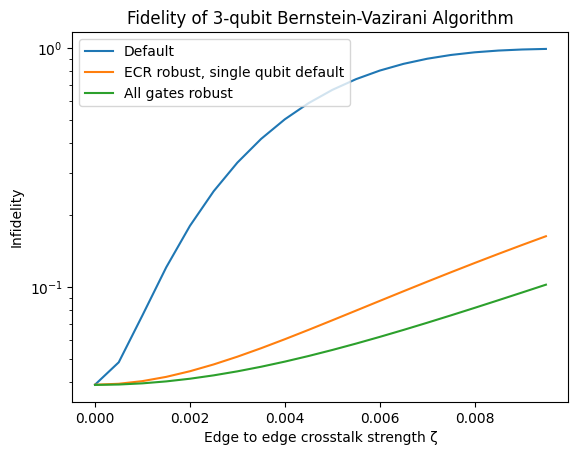

In [98]:
plt.plot(strength_array, 1 - np.array(default_fidelities), label="Default")
plt.plot(strength_array, 1 - np.array(mixed_fidelities), label="ECR robust, single qubit default")
plt.plot(strength_array, 1 - np.array(robust_fidelities), label="All gates robust")
plt.yscale("log")
plt.xlabel("Edge to edge crosstalk strength ζ")
plt.ylabel("Infidelity")
plt.title("Fidelity of 3-qubit Bernstein-Vazirani Algorithm")
plt.legend();

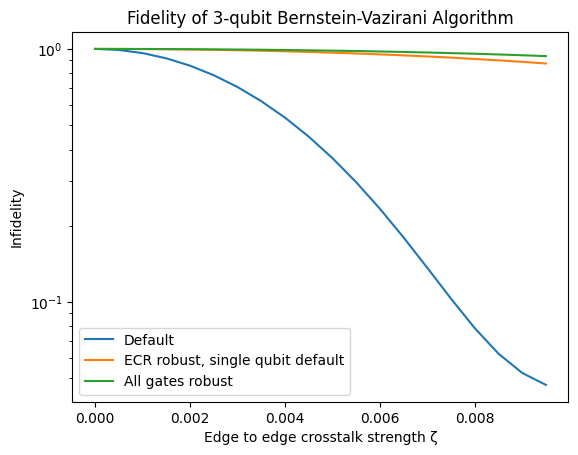

In [99]:
plt.plot(strength_array, 1 + np.array(default_fidelities) - default_fidelities[0], label="Default")
plt.plot(strength_array, 1 + np.array(mixed_fidelities) - mixed_fidelities[0], label="ECR robust, single qubit default")
plt.plot(strength_array, 1 + np.array(robust_fidelities) - robust_fidelities[0], label="All gates robust")
plt.yscale("log")
plt.xlabel("Edge to edge crosstalk strength ζ")
plt.ylabel("Infidelity")
plt.title("Fidelity of 3-qubit Bernstein-Vazirani Algorithm")
plt.legend();

In [95]:
print(f"Robust: {robust_fidelities}")

Robust: [0.961092813451772, 0.9609438277865312, 0.9604968486291018, 0.9597493536154728, 0.9586970132557976, 0.9573336813536314, 0.9556513829275088, 0.9536403007777655, 0.9512887621698263, 0.9485832274314687, 0.9455082825852691, 0.9420466384554607, 0.9381791389984867, 0.9338847819033018, 0.9291407547864851, 0.9239224905603847, 0.9182037457722718, 0.9119567058877489, 0.9051521216111116, 0.8977594803849698]


In [96]:
print(f"ECR robust, single qubit default: {mixed_fidelities}")

ECR robust, single qubit default: [0.9610162947375829, 0.9606586955755657, 0.9596367289869668, 0.9579521690433042, 0.9556053228548893, 0.952595027454427, 0.9489186531959481, 0.9445721152132353, 0.9395498949487968, 0.9338450741941665, 0.92744938446672, 0.9203532748795658, 0.9125460019305266, 0.9040157448331524, 0.8947497501274255, 0.8847345093281228, 0.8739559732818037, 0.8623998066964036, 0.8500516859653197, 0.8368976429170629]
